**Project title:** Food Waste Analysis and Prediction Using Machine Learning


**Objective:**
The objective of this project is to analyze food-waste patterns, predict the quantity of food wasted, classify the reasons for food waste, and discover groups of similar food-waste records using machine-learning techniques.


**Methodology:**
The dataset is cleaned and preprocessed using missing-value imputation, duplicate removal, date feature extraction, categorical encoding, and feature scaling. The processed data is used to train regression and classification models. Clustering algorithms are applied to discover patterns without predefined labels.


**Regression:**
Random Forest Regression, Linear Regression, and XGBoost Regression are evaluated for predicting the quantity of food wasted. MAE, RMSE, and R² are used to assess their predictive performance.


**Classification:**
 XGBoost Classifier, Random Forest Classifier, and KNN Classifier are used to predict the recorded waste reason. Accuracy, precision, recall, F1 score, and confusion matrices are used for evaluation.


**Clustering:**
K-Means clustering, Heirarchial clustering, and DBSCAN used to assign each record degrees of membership across clusters. Cluster summaries are used to interpret food-waste patterns.


**Expected outcome:**
The project aims to identify useful patterns in food waste, compare the predictive performance of different algorithms, and support better food-purchasing and consumption decisions. Actual conclusions should be written after reviewing the model results.

Step 1: Load and prepare the dataset

In [1]:

import pandas as pd

df = pd.read_csv('/content/food_wastage_data.csv')

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()


Dataset Shape: (1782, 11)

Column Names:
['Type of Food', 'Number of Guests', 'Event Type', 'Quantity of Food', 'Storage Conditions', 'Purchase History', 'Seasonality', 'Preparation Method', 'Geographical Location', 'Pricing', 'Wastage Food Amount']

First 5 Rows:


,Type of Food,Number of Guests,Event Type,Quantity of Food,Storage Conditions,Purchase History,Seasonality,Preparation Method,Geographical Location,Pricing,Wastage Food Amount
0,Meat,310,Corporate,450,Refrigerated,Regular,All Seasons,Buffet,Urban,Low,25
1,Meat,400,Birthday,500,Room Temperature,Regular,Winter,Buffet,Suburban,High,40
2,Vegetables,302,Birthday,371,Refrigerated,Regular,Summer,Buffet,Suburban,Low,27
3,Meat,491,Birthday,497,Refrigerated,Regular,All Seasons,Finger Food,Rural,High,32
4,Meat,300,Corporate,400,Refrigerated,Regular,Winter,Finger Food,Urban,Moderate,25



Missing Values:
Type of Food             0
Number of Guests         0
Event Type               0
Quantity of Food         0
Storage Conditions       0
Purchase History         0
Seasonality              0
Preparation Method       0
Geographical Location    0
Pricing                  0
Wastage Food Amount      0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1782 entries, 0 to 1781
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Type of Food           1782 non-null   object
 1   Number of Guests       1782 non-null   int64 
 2   Event Type             1782 non-null   object
 3   Quantity of Food       1782 non-null   int64 
 4   Storage Conditions     1782 non-null   object
 5   Purchase History       1782 non-null   object
 6   Seasonality            1782 non-null   object
 7   Preparation Method     1782 non-null   object
 8   Geographical Location  1782 n

In [2]:

!pip install xgboost


Regression

import libraries

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor


In [4]:

df = pd.read_csv('/content/food_wastage_data.csv')

print("Dataset Shape:", df.shape)
display(df.head())
print(df.columns.tolist())


Dataset Shape: (1782, 11)


,Type of Food,Number of Guests,Event Type,Quantity of Food,Storage Conditions,Purchase History,Seasonality,Preparation Method,Geographical Location,Pricing,Wastage Food Amount
0,Meat,310,Corporate,450,Refrigerated,Regular,All Seasons,Buffet,Urban,Low,25
1,Meat,400,Birthday,500,Room Temperature,Regular,Winter,Buffet,Suburban,High,40
2,Vegetables,302,Birthday,371,Refrigerated,Regular,Summer,Buffet,Suburban,Low,27
3,Meat,491,Birthday,497,Refrigerated,Regular,All Seasons,Finger Food,Rural,High,32
4,Meat,300,Corporate,400,Refrigerated,Regular,Winter,Finger Food,Urban,Moderate,25


['Type of Food', 'Number of Guests', 'Event Type', 'Quantity of Food', 'Storage Conditions', 'Purchase History', 'Seasonality', 'Preparation Method', 'Geographical Location', 'Pricing', 'Wastage Food Amount']


Select input and target

Explanation: X contains the inputs for the model, and Y contains the amount of wasted food that the model needs to predict.

In [5]:

X = df.drop(columns=['Wastage Food Amount'])

y = pd.to_numeric(
    df['Wastage Food Amount'], errors='coerce'
)

valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

print("Input shape:", X.shape)
print("Target shape:", y.shape)


Input shape: (1782, 10)
Target shape: (1782,)


Preprocess the data

Explanation: Categorical text values need to be converted into numerical representations for machine learning models. Any missing input values must be filled.

What happens?
- Numerical missing values → fill with median.
- Categorical missing values → fill with most frequent values.
- Text categories → converted to numerical values using one-hot encoding.

In [6]:

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(include='object').columns.tolist()

preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)


Numerical columns: ['Number of Guests', 'Quantity of Food']
Categorical columns: ['Type of Food', 'Event Type', 'Storage Conditions', 'Purchase History', 'Seasonality', 'Preparation Method', 'Geographical Location', 'Pricing']


Split the dataset

Explanation: split the dataset into 80% training and 20% testing.

In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 1425
Testing records: 357


**Regression Algorithms**

Algorithm 1: XGBoost Regression

Create and train the XGBoost model

What happens?
- n_estimators=300: It uses 300 boosting trees.
- max_depth=5: It limits each tree depth.
- learning_rate=0.05: It controls each boosting step contribution.
- model.fit(): It starts model training

In [8]:

model = Pipeline([
    ('preprocessor', preprocessor),
    ('xgb', XGBRegressor(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        objective='reg:squarederror',
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("XGBoost model training completed!")


XGBoost model training completed!


Predict and evaluate

Metrics meaning:


MAE	Average absolute error

MSE	Average squared error

RMSE	Error in the target's units

R² Score	Model explains about the variation

In [9]:

y_pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))


MAE: 1.8554465770721436
MSE: 7.511646747589111
RMSE: 2.7407383581051863
R2 Score: 0.9275341629981995


Actual vs Predicted graph

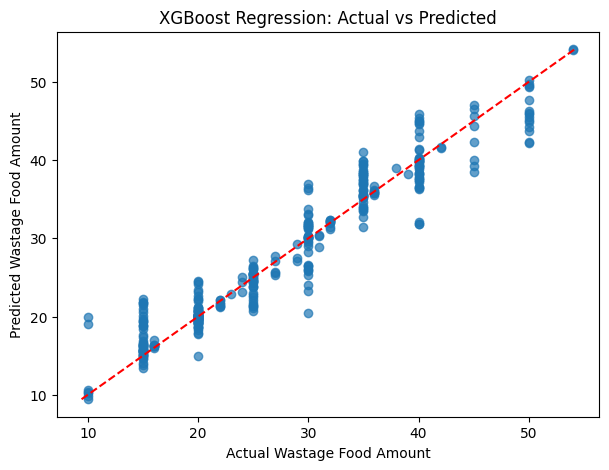

In [10]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], 'r--')

plt.xlabel("Actual Wastage Food Amount")
plt.ylabel("Predicted Wastage Food Amount")
plt.title("XGBoost Regression: Actual vs Predicted")

plt.show()


Algorithm 2: Linear Regression

Explanation: It learns the relationship between the input features and the food wastage amount and makes predictions.

train the model

In [11]:

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

lr_model.fit(X_train, y_train)

print("Linear Regression training completed!")


Linear Regression training completed!


Evaluate the model

In [12]:

lr_pred = lr_model.predict(X_test)

print("Linear Regression Results")
print("MAE:", mean_absolute_error(y_test, lr_pred))
print("MSE:", mean_squared_error(y_test, lr_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("R2 Score:", r2_score(y_test, lr_pred))


Linear Regression Results
MAE: 3.9146146591781905
MSE: 25.256443409844618
RMSE: 5.0255789129059165
R2 Score: 0.7563478558273058


Actual vs Predicted Graph

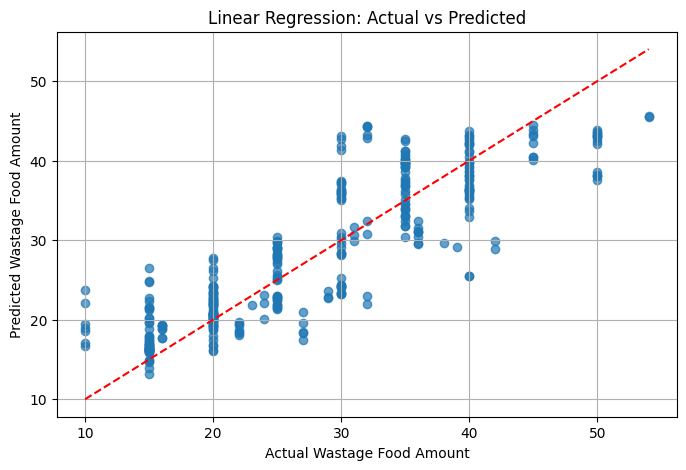

In [13]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, lr_pred, alpha=0.7)

low = min(y_test.min(), lr_pred.min())
high = max(y_test.max(), lr_pred.max())

plt.plot([low, high], [low, high], 'r--')

plt.xlabel("Actual Wastage Food Amount")
plt.ylabel("Predicted Wastage Food Amount")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(True)
plt.show()


Algorithm 3: Random Forest Regressor

Explanation: It trains multiple decision trees, combines their predictions, and estimates the food wastage amount. It can also learn non-linear patterns.

Train the model

In [14]:

from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


Random Forest training completed!


Evaluate the model

In [15]:

rf_pred = rf_model.predict(X_test)

print("Random Forest Results")
print("MAE:", mean_absolute_error(y_test, rf_pred))
print("MSE:", mean_squared_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2 Score:", r2_score(y_test, rf_pred))


Random Forest Results
MAE: 1.6430504757458537
MSE: 7.69618424069394
RMSE: 2.7741997478000644
R2 Score: 0.9257539249781205


Actual vs Predicted Graph

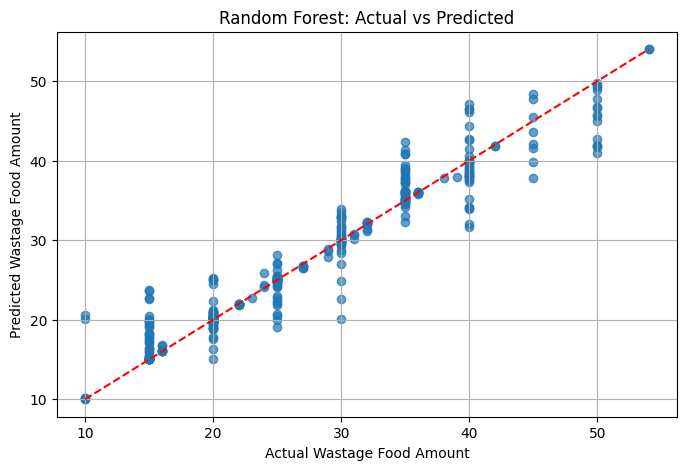

In [16]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_pred, alpha=0.7)

low = min(y_test.min(), rf_pred.min())
high = max(y_test.max(), rf_pred.max())

plt.plot([low, high], [low, high], 'r--')

plt.xlabel("Actual Wastage Food Amount")
plt.ylabel("Predicted Wastage Food Amount")
plt.title("Random Forest: Actual vs Predicted")
plt.grid(True)
plt.show()


Final: Compare all 3 regression algorithms

Your XGBoost model has already been trained and y_pred predictions have been generated. If you run this cell, you can compare the results of the three algorithms side-by-side.

How to choose the best model:
- Lowest MAE and RMSE generally indicate smaller prediction errors.
- Highest R² generally indicates better explanatory performance on this test split.

In [17]:

results = pd.DataFrame({
    'Algorithm': [
        'XGBoost',
        'Linear Regression',
        'Random Forest'
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, rf_pred)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred))
    ],
    'R2 Score': [
        r2_score(y_test, y_pred),
        r2_score(y_test, lr_pred),
        r2_score(y_test, rf_pred)
    ]
})

display(results.round(3))


,Algorithm,MAE,RMSE,R2 Score
0,XGBoost,1.855,2.741,0.928
1,Linear Regression,3.915,5.026,0.756
2,Random Forest,1.643,2.774,0.926


Classification

Import libraries

In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier


Load dataset

In [19]:

df = pd.read_csv('/content/food_wastage_data.csv')

print("Dataset Shape:", df.shape)
display(df.head())
print(df.columns.tolist())


Dataset Shape: (1782, 11)


,Type of Food,Number of Guests,Event Type,Quantity of Food,Storage Conditions,Purchase History,Seasonality,Preparation Method,Geographical Location,Pricing,Wastage Food Amount
0,Meat,310,Corporate,450,Refrigerated,Regular,All Seasons,Buffet,Urban,Low,25
1,Meat,400,Birthday,500,Room Temperature,Regular,Winter,Buffet,Suburban,High,40
2,Vegetables,302,Birthday,371,Refrigerated,Regular,Summer,Buffet,Suburban,Low,27
3,Meat,491,Birthday,497,Refrigerated,Regular,All Seasons,Finger Food,Rural,High,32
4,Meat,300,Corporate,400,Refrigerated,Regular,Winter,Finger Food,Urban,Moderate,25


['Type of Food', 'Number of Guests', 'Event Type', 'Quantity of Food', 'Storage Conditions', 'Purchase History', 'Seasonality', 'Preparation Method', 'Geographical Location', 'Pricing', 'Wastage Food Amount']


Create Low, Medium, High categories

Explanation: We divide the numerical value of Wastage Food Amount into three groups. qcut creates these groups based on the dataset distribution.

In [20]:

target_col = 'Wastage Food Amount'

df[target_col] = pd.to_numeric(df[target_col], errors='coerce')
df = df.dropna(subset=[target_col]).copy()

bins = pd.qcut(df[target_col], q=3, labels=False, duplicates='drop')

df['Wastage Category'] = bins.map({
    0: 'Low',
    1: 'Medium',
    2: 'High'
})

df = df.dropna(subset=['Wastage Category'])

print(df['Wastage Category'].value_counts())


Wastage Category
Medium    773
Low       594
High      415
Name: count, dtype: int64


Prepare input and output

Explanation:
- X = input features.
- y = category we want to predict.
- we will remove original wastage amount and category columns from the input to prevent data leakage

In [21]:

X = df.drop(columns=[target_col, 'Wastage Category'])
y = df['Wastage Category']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Training records: 1425
Testing records: 357


Preprocess the data

Explanation: We fill numerical missing values with the median, and categorical missing values with the most-frequent value. We perform One-Hot Encoding on text columns. We scale numerical features for KNN.

In [22]:

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

def make_preprocessor(scale_numeric=False):
    num_steps = [
        ('imputer', SimpleImputer(strategy='median'))
    ]

    if scale_numeric:
        num_steps.append(('scaler', StandardScaler()))

    return ColumnTransformer([
        ('num', Pipeline(num_steps), num_cols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), cat_cols)
    ])


**Classification Algorithms**

Algorithm 1: Random Forest Classifier

Explanation: Random Forest uses multiple decision trees to predict the final class.

In [23]:

rf_model = Pipeline([
    ('preprocessor', make_preprocessor()),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred, zero_division=0))


Random Forest Accuracy: 0.8571428571428571
              precision    recall  f1-score   support

        High       0.87      0.81      0.84        83
         Low       0.88      0.92      0.90       119
      Medium       0.83      0.84      0.84       155

    accuracy                           0.86       357
   macro avg       0.86      0.85      0.86       357
weighted avg       0.86      0.86      0.86       357



Algorithms 2: XGBoost Classifier

Explanation: XGBoost builds trees sequentially by correcting the mistakes of previous trees. For this model, class labels are encoded as numbers.

In [24]:

class_names = ['Low', 'Medium', 'High']
class_to_num = {name: i for i, name in enumerate(class_names)}

y_train_num = y_train.map(class_to_num)
y_test_num = y_test.map(class_to_num)

xgb_model = Pipeline([
    ('preprocessor', make_preprocessor()),
    ('classifier', XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        objective='multi:softprob',
        num_class=3,
        eval_metric='mlogloss',
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train_num)
xgb_pred_num = xgb_model.predict(X_test).astype(int)
xgb_pred = pd.Series(xgb_pred_num, index=y_test.index).map(
    {v: k for k, v in class_to_num.items()}
)

print("XGBoost Accuracy:",
      accuracy_score(y_test, xgb_pred))
print(classification_report(y_test, xgb_pred, zero_division=0))


XGBoost Accuracy: 0.8823529411764706
              precision    recall  f1-score   support

        High       0.91      0.84      0.88        83
         Low       0.89      0.93      0.91       119
      Medium       0.86      0.86      0.86       155

    accuracy                           0.88       357
   macro avg       0.89      0.88      0.88       357
weighted avg       0.88      0.88      0.88       357



KNN Classifier

Explanation: KNN identifies the 5 nearest similar records and predicts the majority category. Scaling numerical features ensures that different units do not unfairly affect the model.

In [25]:

knn_model = Pipeline([
    ('preprocessor', make_preprocessor(scale_numeric=True)),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

print("KNN Accuracy:",
      accuracy_score(y_test, knn_pred))
print(classification_report(y_test, knn_pred, zero_division=0))


KNN Accuracy: 0.7478991596638656
              precision    recall  f1-score   support

        High       0.77      0.65      0.71        83
         Low       0.76      0.89      0.82       119
      Medium       0.72      0.69      0.71       155

    accuracy                           0.75       357
   macro avg       0.75      0.74      0.74       357
weighted avg       0.75      0.75      0.74       357



Compare all three algorithms

Explanation: We compare the accuracy of three models on the same test dataset. The model with the highest accuracy is the best candidate; F1-score should also be considered.

,Algorithm,Accuracy (%)
0,Random Forest,85.71
1,XGBoost,88.24
2,KNN,74.79


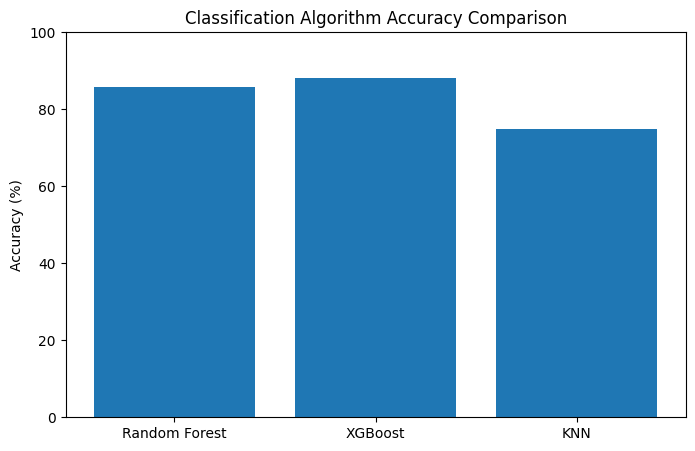

In [26]:

results = pd.DataFrame({
    'Algorithm': [
        'Random Forest',
        'XGBoost',
        'KNN'
    ],
    'Accuracy': [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred),
        accuracy_score(y_test, knn_pred)
    ]
})

results['Accuracy (%)'] = results['Accuracy'] * 100
display(results[['Algorithm', 'Accuracy (%)']].round(2))

plt.figure(figsize=(8, 5))
plt.bar(results['Algorithm'], results['Accuracy (%)'])
plt.ylabel('Accuracy (%)')
plt.title('Classification Algorithm Accuracy Comparison')
plt.ylim(0, 100)
plt.show()


Confusion matrix graphs

Explanation: We can check using a confusion matrix whether each model correctly predicted the Low, Medium, and High categories.

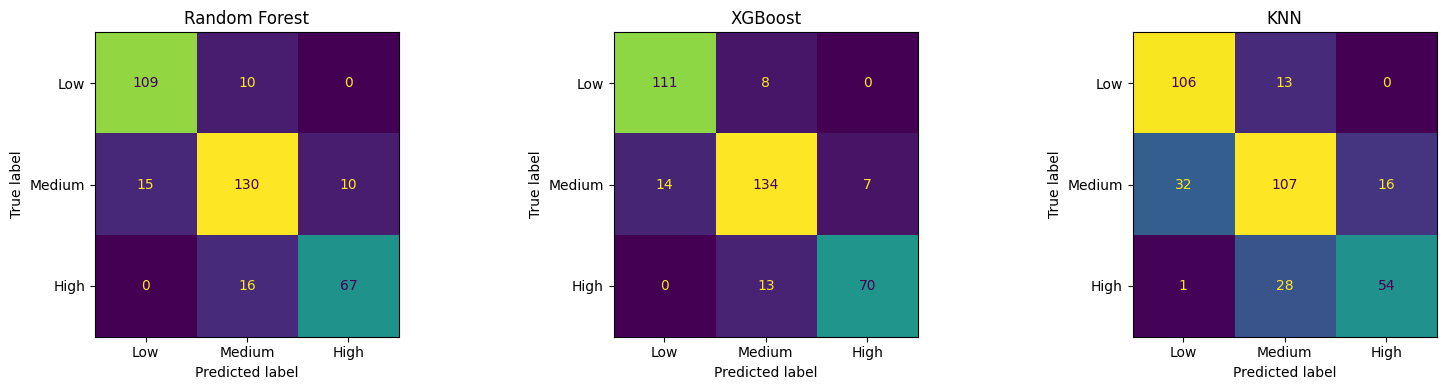

In [27]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

models = [
    ('Random Forest', y_test, rf_pred),
    ('XGBoost', y_test, xgb_pred),
    ('KNN', y_test, knn_pred)
]

for ax, (name, actual, predicted) in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        actual,
        predicted,
        labels=['Low', 'Medium', 'High'],
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


Clustering

In classification, we predicted Low, Medium, and High categories. However, in clustering, without predefined labels, we divide similar records into groups.

Example:
- Cluster 0 — similar food-waste patterns
- Cluster 1 — different food-waste patterns
- Cluster 2 — another type of food-waste pattern

import libraries

In [28]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import TruncatedSVD


load dataset

In [29]:

df = pd.read_csv('/content/food_wastage_data.csv')

print("Dataset Shape:", df.shape)
display(df.head())
print(df.columns.tolist())


Dataset Shape: (1782, 11)


,Type of Food,Number of Guests,Event Type,Quantity of Food,Storage Conditions,Purchase History,Seasonality,Preparation Method,Geographical Location,Pricing,Wastage Food Amount
0,Meat,310,Corporate,450,Refrigerated,Regular,All Seasons,Buffet,Urban,Low,25
1,Meat,400,Birthday,500,Room Temperature,Regular,Winter,Buffet,Suburban,High,40
2,Vegetables,302,Birthday,371,Refrigerated,Regular,Summer,Buffet,Suburban,Low,27
3,Meat,491,Birthday,497,Refrigerated,Regular,All Seasons,Finger Food,Rural,High,32
4,Meat,300,Corporate,400,Refrigerated,Regular,Winter,Finger Food,Urban,Moderate,25


['Type of Food', 'Number of Guests', 'Event Type', 'Quantity of Food', 'Storage Conditions', 'Purchase History', 'Seasonality', 'Preparation Method', 'Geographical Location', 'Pricing', 'Wastage Food Amount']


Prepare the data

Explanation: Clustering ki predefined target labels avasaram ledu. Similarity base cheskoni groups create chestham. Food wastage patterns ni group cheyadaniki original Wastage Food Amount feature ni retain chestham, but already-created Wastage Category column ni use cheyyamu.

In [30]:

cluster_df = df.copy()

cluster_df = cluster_df.drop(
    columns=['Wastage Category'],
    errors='ignore'
)

# Remove ID-like columns if present
id_cols = [
    col for col in cluster_df.columns
    if col.lower() in ['id', 'record_id', 'event_id']
]
cluster_df = cluster_df.drop(columns=id_cols)

# Convert wastage amount to numeric, if present
if 'Wastage Food Amount' in cluster_df.columns:
    cluster_df['Wastage Food Amount'] = pd.to_numeric(
        cluster_df['Wastage Food Amount'],
        errors='coerce'
    )

print("Data ready for clustering:", cluster_df.shape)


Data ready for clustering: (1782, 11)


Preprocess the data

Explanation: We fill missing values, encode categorical features, and scale numeric features. Since clustering is distance-based, scaling is important.

In [31]:

num_cols = cluster_df.select_dtypes(
    include='number'
).columns.tolist()

cat_cols = cluster_df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

X_cluster = preprocessor.fit_transform(cluster_df)

print("Preprocessed shape:", X_cluster.shape)


Preprocessed shape: (1782, 28)


**Clustering Algorithms**

Algorithm 1: K-Means Clustering

Explanation: K-Means divides the records into 3 clusters. Similar records will be in the same cluster.

In [32]:

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_cluster)

print("K-Means Cluster Counts:")
print(pd.Series(kmeans_labels).value_counts().sort_index())


K-Means Cluster Counts:
0    698
1    595
2    489
Name: count, dtype: int64


Algorithm 2: Hierarchical Clustering

Explanation: Hierarchical clustering combines similar records into groups step-by-step. In this example, we create 3 clusters.

In [33]:

hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

hierarchical_labels = hierarchical.fit_predict(
    X_cluster.toarray()
    if hasattr(X_cluster, "toarray")
    else X_cluster
)

print("Hierarchical Cluster Counts:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())


Hierarchical Cluster Counts:
0    870
1    610
2    302
Name: count, dtype: int64


Algorithm 3: DBSCAN Clustering

Explanation: DBSCAN identifies groups in dense regions. Outliers can be marked with a -1 label. The result changes depending on the eps and min_samples parameters.

DBSCAN Full Form:**Density-Based Spatial Clustering of Applications with Noise.**

Meaning:

DBSCAN is an unsupervised machine learning clustering algorithm that groups data points based on their density and identifies unusual points as noise or outliers.

How it works:
- Dense regions: Groups similar data points into clusters.
- Sparse regions: Points that don't belong to any cluster may be marked as noise (-1).
- No need to specify K: Unlike K-Means, we don't need to specify the number of clusters beforehand.
Example in your Food Waste project:
- Cluster 0: Records with similar food-wastage patterns.
- Cluster 1: Another group of similar records.
- Noise (-1): Records that don't fit into the identified dense clusters.

In [34]:

dbscan = DBSCAN(
    eps=1.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_cluster)

print("DBSCAN Cluster Counts:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

print("Number of clusters (excluding noise):",
      len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0))

print("Noise records:", np.sum(dbscan_labels == -1))


DBSCAN Cluster Counts:
-1     735
 0     891
 1       8
 2       7
 3      20
 4       3
 5       6
 6      32
 7       8
 8       6
 9      11
 10     12
 11      4
 12      5
 13      9
 14      5
 15      5
 16      5
 17      5
 18      5
Name: count, dtype: int64
Number of clusters (excluding noise): 19
Noise records: 735


Visualize the clusters

Explanation: When there are many features, we reduce the data to 2 dimensions using TruncatedSVD and visualize the clusters in a graph.

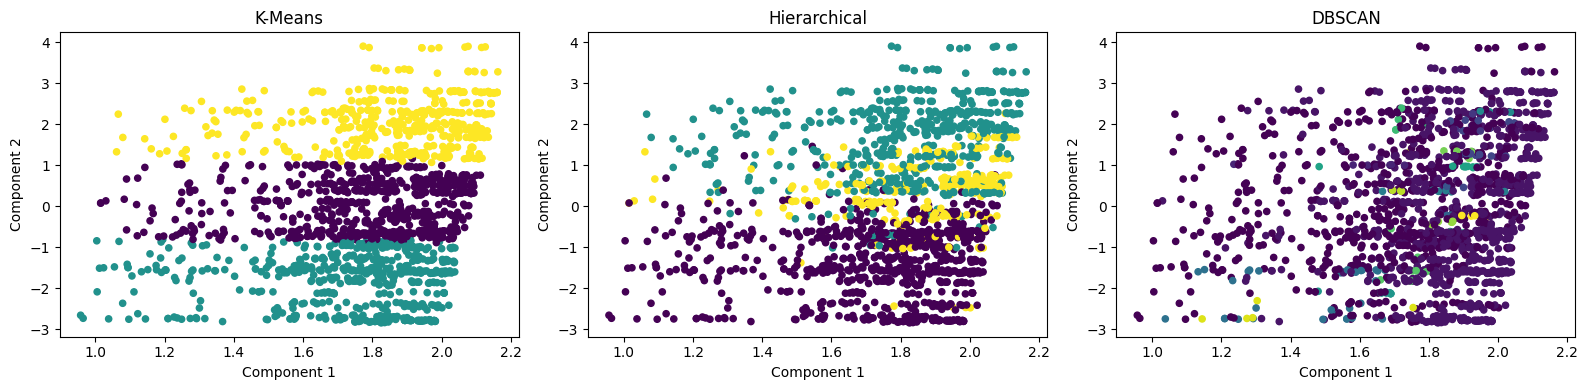

In [35]:

X_dense = (
    X_cluster.toarray()
    if hasattr(X_cluster, "toarray")
    else X_cluster
)

svd = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd.fit_transform(X_dense)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

cluster_results = [
    ("K-Means", kmeans_labels),
    ("Hierarchical", hierarchical_labels),
    ("DBSCAN", dbscan_labels)
]

for ax, (name, labels) in zip(axes, cluster_results):
    ax.scatter(
        X_2d[:, 0],
        X_2d[:, 1],
        c=labels,
        cmap='viridis',
        s=20
    )
    ax.set_title(name)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")

plt.tight_layout()
plt.show()


Compare the cluster results

In [36]:

comparison = pd.DataFrame({
    'Algorithm': ['K-Means', 'Hierarchical', 'DBSCAN'],
    'Number of Clusters': [
        len(set(kmeans_labels)),
        len(set(hierarchical_labels)),
        len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
    ],
    'Noise Records': [
        0,
        0,
        int(np.sum(dbscan_labels == -1))
    ]
})

display(comparison)


,Algorithm,Number of Clusters,Noise Records
0,K-Means,3,0
1,Hierarchical,3,0
2,DBSCAN,19,735


To print Noisy Data / Outliers

Explanation
- dbscan_labels == -1 → Selects the records identified as noise by DBSCAN.
- noise_data → Stores all those records.
- len(noise_data) → Prints the total count of noisy records.
- display(noise_data) → Displays the complete table of noisy records.

In [37]:
# Identify noisy records
noise_data = cluster_df[dbscan_labels == -1]

print("Total Noisy Records:", len(noise_data))
print("\nNoisy Data Values:")

display(noise_data)

Total Noisy Records: 735

Noisy Data Values:


,Type of Food,Number of Guests,Event Type,Quantity of Food,Storage Conditions,Purchase History,Seasonality,Preparation Method,Geographical Location,Pricing,Wastage Food Amount
0,Meat,310,Corporate,450,Refrigerated,Regular,All Seasons,Buffet,Urban,Low,25
1,Meat,400,Birthday,500,Room Temperature,Regular,Winter,Buffet,Suburban,High,40
2,Vegetables,302,Birthday,371,Refrigerated,Regular,Summer,Buffet,Suburban,Low,27
3,Meat,491,Birthday,497,Refrigerated,Regular,All Seasons,Finger Food,Rural,High,32
5,Meat,302,Birthday,371,Refrigerated,Regular,Summer,Buffet,Suburban,Low,27
...,...,...,...,...,...,...,...,...,...,...,...
1770,Meat,320,Birthday,400,Refrigerated,Occasional,Summer,Finger Food,Suburban,Moderate,20
1772,Fruits,429,Wedding,496,Room Temperature,Regular,Summer,Sit-down Dinner,Suburban,Low,42
1775,Meat,350,Birthday,450,Room Temperature,Regular,Winter,Sit-down Dinner,Urban,Moderate,25
1776,Meat,491,Social Gathering,497,Room Temperature,Regular,Winter,Finger Food,Urban,High,32


In [38]:
display(noise_data[['Wastage Food Amount']])

,Wastage Food Amount
0,25
1,40
2,27
3,32
5,27
...,...
1770,20
1772,42
1775,25
1776,32


In [39]:

import os
import shutil
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score
)
from google.colab import files

# ==========================================
# 1. CREATE OUTPUT FOLDER
# ==========================================
output_folder = "/content/food_waste_outputs"
os.makedirs(output_folder, exist_ok=True)

metrics = []

# ==========================================
# 2. REGRESSION OUTPUT
# Requires: best_regressor, X_test, y_test
# ==========================================
if all(name in globals() for name in ["best_regressor", "X_test", "y_test"]):
    y_pred = best_regressor.predict(X_test)

    regression_output = pd.DataFrame({
        "Actual Wastage": np.asarray(y_test).ravel(),
        "Predicted Wastage": np.asarray(y_pred).ravel()
    })

    regression_output.to_csv(
        f"{output_folder}/regression_predictions.csv", index=False
    )

    metrics.extend([
        {"Model": "Regression", "Metric": "MAE",
         "Value": mean_absolute_error(y_test, y_pred)},
        {"Model": "Regression", "Metric": "MSE",
         "Value": mean_squared_error(y_test, y_pred)},
        {"Model": "Regression", "Metric": "RMSE",
         "Value": np.sqrt(mean_squared_error(y_test, y_pred))},
        {"Model": "Regression", "Metric": "R2",
         "Value": r2_score(y_test, y_pred)}
    ])
    print("Regression output saved.")
else:
    print("Regression skipped: model or test variables not found.")

# ==========================================
# 3. CLASSIFICATION OUTPUT
# Requires: best_classifier, X_test_cls, y_test_cls
# ==========================================
if all(name in globals() for name in [
    "best_classifier", "X_test_cls", "y_test_cls"
]):
    y_cls_pred = best_classifier.predict(X_test_cls)

    classification_output = pd.DataFrame({
        "Actual Category": np.asarray(y_test_cls).ravel(),
        "Predicted Category": np.asarray(y_cls_pred).ravel()
    })

    classification_output.to_csv(
        f"{output_folder}/classification_predictions.csv", index=False
    )

    metrics.extend([
        {"Model": "Classification", "Metric": "Accuracy",
         "Value": accuracy_score(y_test_cls, y_cls_pred)},
        {"Model": "Classification", "Metric": "Precision",
         "Value": precision_score(
             y_test_cls, y_cls_pred,
             average="weighted", zero_division=0)},
        {"Model": "Classification", "Metric": "Recall",
         "Value": recall_score(
             y_test_cls, y_cls_pred,
             average="weighted", zero_division=0)},
        {"Model": "Classification", "Metric": "F1 Score",
         "Value": f1_score(
             y_test_cls, y_cls_pred,
             average="weighted", zero_division=0)}
    ])
    print("Classification output saved.")
else:
    print("Classification skipped: model or test variables not found.")

# ==========================================
# 4. K-MEANS CLUSTERING OUTPUT
# Requires: cluster_df, kmeans_labels
# ==========================================
if all(name in globals() for name in ["cluster_df", "kmeans_labels"]):
    kmeans_output = cluster_df.copy()
    kmeans_output["KMeans_Cluster"] = np.asarray(kmeans_labels)
    kmeans_output.to_csv(
        f"{output_folder}/kmeans_clusters.csv", index=False
    )
    print("K-Means output saved.")
else:
    print("K-Means skipped: cluster_df or kmeans_labels not found.")

# ==========================================
# 5. HIERARCHICAL CLUSTERING OUTPUT
# Requires: cluster_df, hierarchical_labels
# ==========================================
if all(name in globals() for name in [
    "cluster_df", "hierarchical_labels"
]):
    hierarchical_output = cluster_df.copy()
    hierarchical_output["Hierarchical_Cluster"] = np.asarray(
        hierarchical_labels
    )
    hierarchical_output.to_csv(
        f"{output_folder}/hierarchical_clusters.csv", index=False
    )
    print("Hierarchical output saved.")
else:
    print("Hierarchical skipped: hierarchical_labels not found.")

# ==========================================
# 6. DBSCAN CLUSTERING + NOISE RECORDS
# Requires: cluster_df, dbscan_labels
# ==========================================
if all(name in globals() for name in ["cluster_df", "dbscan_labels"]):
    dbscan_output = cluster_df.copy()
    dbscan_output["DBSCAN_Cluster"] = np.asarray(dbscan_labels)

    dbscan_output.to_csv(
        f"{output_folder}/dbscan_clusters.csv", index=False
    )

    noise_data = dbscan_output[
        dbscan_output["DBSCAN_Cluster"] == -1
    ]
    noise_data.to_csv(
        f"{output_folder}/dbscan_noise_records.csv", index=False
    )

    print("DBSCAN output saved.")
    print("Total noisy records:", len(noise_data))
else:
    print("DBSCAN skipped: dbscan_labels not found.")

# ==========================================
# 7. SAVE MODEL METRICS
# ==========================================
if metrics:
    metrics_df = pd.DataFrame(metrics)
    metrics_df.to_csv(
        f"{output_folder}/model_metrics.csv", index=False
    )
    print("\nModel Metrics:")
    display(metrics_df)
else:
    print("No model metrics generated.")

# ==========================================
# 8. SAVE DATASET COPY
# ==========================================
dataset_path = "/content/food_wastage_data(1).csv"

if os.path.exists(dataset_path):
    df = pd.read_csv(dataset_path)
    df.to_csv(
        f"{output_folder}/food_wastage_dataset.csv", index=False
    )
    print("Dataset copy saved.")

# ==========================================
# 9. CREATE ZIP FILE
# ==========================================
zip_path = shutil.make_archive(
    "/content/food_waste_output_files",
    "zip",
    output_folder
)

print("\nGenerated output files:")
for filename in sorted(os.listdir(output_folder)):
    print("-", filename)

print("\nZIP created:", zip_path)

# ==========================================
# 10. DOWNLOAD ZIP
# ==========================================
files.download(zip_path)


Regression skipped: model or test variables not found.
Classification skipped: model or test variables not found.
K-Means output saved.
Hierarchical output saved.
DBSCAN output saved.
Total noisy records: 735
No model metrics generated.

Generated output files:
- dbscan_clusters.csv
- dbscan_noise_records.csv
- hierarchical_clusters.csv
- kmeans_clusters.csv

ZIP created: /content/food_waste_output_files.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:

import pandas as pd
import numpy as np
import os
import shutil

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score
)
from sklearn.base import clone

output_folder = "/content/food_waste_outputs"
os.makedirs(output_folder, exist_ok=True)

# Load dataset
df = pd.read_csv("/content/food_wastage_data.csv")
df.columns = df.columns.str.strip()

target = "Wastage Food Amount"

if target not in df.columns:
    raise ValueError(
        f"Target column '{target}' not found. Available columns: {df.columns.tolist()}"
    )

# Remove rows without target
data = df.dropna(subset=[target]).copy()

# Features and regression target
X = data.drop(columns=[target])
y = pd.to_numeric(data[target], errors="coerce")

valid = y.notna()
X = X.loc[valid].copy()
y = y.loc[valid].copy()

# Detect numerical and categorical columns
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

# Split once for regression
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

reg_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=200, random_state=42
    ))
])

reg_model.fit(X_train, y_train)
reg_pred = reg_model.predict(X_test)

pd.DataFrame({
    "Actual Wastage": y_test.to_numpy(),
    "Predicted Wastage": reg_pred
}).to_csv(
    f"{output_folder}/regression_predictions.csv", index=False
)

# Classification categories from wastage amounts
class_labels = pd.qcut(
    y, q=3, labels=["Low", "Medium", "High"], duplicates="drop"
)

# Align classification data with the valid regression rows
X_cls = X.loc[class_labels.index]
y_cls = class_labels

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42,
    stratify=y_cls
)

cls_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight="balanced"
    ))
])

cls_model.fit(X_train_c, y_train_c)
cls_pred = cls_model.predict(X_test_c)

pd.DataFrame({
    "Actual Category": np.asarray(y_test_c),
    "Predicted Category": cls_pred
}).to_csv(
    f"{output_folder}/classification_predictions.csv", index=False
)

# Calculate real metrics from this train/test split
metrics = [
    {"Model": "Random Forest Regressor", "Metric": "MAE",
     "Value": mean_absolute_error(y_test, reg_pred)},
    {"Model": "Random Forest Regressor", "Metric": "MSE",
     "Value": mean_squared_error(y_test, reg_pred)},
    {"Model": "Random Forest Regressor", "Metric": "RMSE",
     "Value": np.sqrt(mean_squared_error(y_test, reg_pred))},
    {"Model": "Random Forest Regressor", "Metric": "R2",
     "Value": r2_score(y_test, reg_pred)},
    {"Model": "Random Forest Classifier", "Metric": "Accuracy",
     "Value": accuracy_score(y_test_c, cls_pred)},
    {"Model": "Random Forest Classifier", "Metric": "Precision",
     "Value": precision_score(y_test_c, cls_pred,
                              average="weighted", zero_division=0)},
    {"Model": "Random Forest Classifier", "Metric": "Recall",
     "Value": recall_score(y_test_c, cls_pred,
                           average="weighted", zero_division=0)},
    {"Model": "Random Forest Classifier", "Metric": "F1 Score",
     "Value": f1_score(y_test_c, cls_pred,
                       average="weighted", zero_division=0)}
]

pd.DataFrame(metrics).to_csv(
    f"{output_folder}/model_metrics.csv", index=False
)

# Save the trained models for future use
import joblib

joblib.dump(reg_model, f"{output_folder}/regression_model.joblib")
joblib.dump(cls_model, f"{output_folder}/classification_model.joblib")

# Show results
print("Regression and classification outputs created.")
print("\nModel metrics:")
display(pd.DataFrame(metrics))

print("\nOutput files:")
for filename in sorted(os.listdir(output_folder)):
    print(filename)

# Create updated ZIP with all available outputs
zip_path = shutil.make_archive(
    "/content/food_waste_output_files",
    "zip",
    output_folder
)

print("\nZIP created:", zip_path)

from google.colab import files
files.download(zip_path)


Regression and classification outputs created.

Model metrics:


,Model,Metric,Value
0,Random Forest Regressor,MAE,1.656140
1,Random Forest Regressor,MSE,7.663543
2,Random Forest Regressor,RMSE,2.768311
3,Random Forest Regressor,R2,0.926069
4,Random Forest Classifier,Accuracy,0.857143
5,Random Forest Classifier,Precision,0.857121
6,Random Forest Classifier,Recall,0.857143
7,Random Forest Classifier,F1 Score,0.856727



Output files:
classification_model.joblib
classification_predictions.csv
dbscan_clusters.csv
dbscan_noise_records.csv
hierarchical_clusters.csv
kmeans_clusters.csv
model_metrics.csv
regression_model.joblib
regression_predictions.csv

ZIP created: /content/food_waste_output_files.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>